# Differential Evolution (DE) untuk Alokasi Dana Saham LQ45 dengan Batas Risiko dan Kardinalitas

Cardinality = maksimal K, kromosom = 2N+1 (85 angka untuk N=42), uang kas boleh dipilih.

> Catatan: fungsi Problem, decoder, dan Evaluator di bagian awal sebagai **fondasi sementara**. Setelah modul bersama di `src/` selesai, bagian ini akan diganti dengan `import` dari modul bersama.

## 1. Pengaturan dan data

In [14]:
import os, sys, time, subprocess
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# --- lokasi data: lokal (root proyek atau notebooks/) maupun Google Colab ---
REPO_URL = "https://github.com/hanscakrawangsa15/OptimasiPortofolioSaham.git"


def cari_root():
    for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "OptimasiPortofolioSaham"):
        if (p / "data" / "windows" / "kasus_tetap.npz").exists():
            return p
    return None


ROOT = cari_root()
if ROOT is None:                       # mis. Google Colab: hanya notebook ini yang ada -> unduh repo (publik)
    print("Data tidak ditemukan di folder kerja; mengunduh repositori dari GitHub ...")
    tujuan = Path.cwd() / "OptimasiPortofolioSaham"
    if not tujuan.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(tujuan)], check=True)
    ROOT = cari_root()
    assert ROOT is not None, "data/windows/*.npz tidak ada di repositori; jalankan python3 src/scrappingdata.py"

# --- parameter masalah ---
RF            = 0.05                      # return kas / risk-free, 5% per tahun
LOT           = 100                       # 100 lembar per lot
D             = 5_000_000.0               # modal (Rp)
K_LIST        = [2, 3, 5, 7, 10]          # batas jumlah saham
SIGMA_MULT    = 1.5                       # sigma_max = 1,5 x volatilitas portofolio 1/N
CAP           = 0.20                      # 20% per saham
CAP_MULAI_K   = 7                         # hanya untuk K >= 7
BUDGET        = 20_000                    # anggaran evaluasi per run
HISTORY_STEP  = 200                       # riwayat konvergensi dicatat tiap 200 evaluasi

np.set_printoptions(precision=4, suppress=True, linewidth=120)
print("ROOT =", ROOT)
print(f"D = Rp {D:,.0f} | rf = {RF:.0%} | cap = {CAP:.0%} (K >= {CAP_MULAI_K}) | anggaran = {BUDGET:,} evaluasi")

ROOT = c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham
D = Rp 5,000,000 | rf = 5% | cap = 20% (K >= 7) | anggaran = 20,000 evaluasi


## 2. Problem

In [15]:
@dataclass(frozen=True)
class Problem:
    mu: np.ndarray            # (N,) return tahunan (return sederhana)
    cov: np.ndarray           # (N,N) kovarians tahunan
    price: np.ndarray         # (N,) harga raw (tanpa penyesuaian) pada hari beli
    D: float                  # modal (Rp)
    K: int                    # batas jumlah saham
    sigma_max: float          # batas volatilitas portofolio
    cap: float = 1.0          # batas bobot per saham; 1.0 = tanpa batas (K < 7)
    lot: int = 100
    rf: float = 0.05
    tickers: tuple = ()
    label: str = ""

    @property
    def n(self) -> int:                 # jumlah saham N
        return len(self.mu)

    @property
    def n_genes(self) -> int:           # panjang kromosom = 2N+1
        return 2 * self.n + 1

    @property
    def harga_lot(self) -> np.ndarray:  # biaya 1 lot tiap saham (Rp)
        return self.lot * self.price

    @property
    def layak_beli(self) -> np.ndarray: # saham yang 1 lot-nya muat dalam D x cap
        return self.harga_lot <= self.D * self.cap

    @property
    def vol(self) -> np.ndarray:        # volatilitas tahunan tiap saham
        return np.sqrt(np.diag(self.cov))


@dataclass
class Result:
    lots: np.ndarray          # (N,) lot terbaik (bilangan bulat)
    R: float                  # return ekspektasi (in-sample)
    sigma: float              # volatilitas portofolio
    viol: float               # max(0, sigma - sigma_max); 0 bila layak
    feasible: bool
    history: list             # [(n_eval, R terbaik yang layak)] tiap 200 evaluasi
    n_eval: int
    seconds: float
    seed: int
    x: np.ndarray = None      # kromosom terbaik
    n_eval_best: int = 0      # evaluasi ke-berapa solusi terbaik ditemukan
    status: str = ""
    trace: dict = None        # jejak per generasi (untuk visualisasi proses GA)


def muat_jendela(nama):
    # Baca data/windows/<nama>.npz (dibuat oleh src/scrappingdata.py): statistik latih, harga beli, sigma_max.
    z = np.load(ROOT / "data" / "windows" / f"{nama}.npz", allow_pickle=False)
    return dict(
        tickers=[str(t) for t in z["tickers"]],
        tanggal_latih_awal=str(z["tanggal_latih_awal"]), tanggal_latih_akhir=str(z["tanggal_latih_akhir"]),
        tanggal_uji_awal=str(z["tanggal_uji_awal"]), tanggal_uji_akhir=str(z["tanggal_uji_akhir"]),
        mu=z["mu"], cov=z["cov"], harga_beli=z["harga_beli"],
        return_uji=z["return_uji"], tanggal_uji=[str(t) for t in z["tanggal_uji"]],   # hanya untuk evaluasi; TIDAK masuk Problem
        vol_benchmark=float(z["vol_benchmark"]),
        sigma_max={float(m): float(v) for m, v in zip(z["sigma_mult"], z["sigma_max"])})


def buat_problem(w, K, D=D, mult=SIGMA_MULT, label=""):
    return Problem(
        mu=w["mu"], cov=w["cov"], price=w["harga_beli"], D=D, K=K,
        sigma_max=w["sigma_max"][mult],
        cap=CAP if K >= CAP_MULAI_K else 1.0,
        lot=LOT, rf=RF, tickers=tuple(t.replace(".JK", "") for t in w["tickers"]), label=label)


# 5 jendela walk-forward + 1 kasus tetap
NAMA_DATA = ["kasus_tetap", "jendela_1", "jendela_2", "jendela_3", "jendela_4", "jendela_5"]
DATA = {nama: muat_jendela(nama) for nama in NAMA_DATA}

w = DATA["kasus_tetap"]
print("Kasus tetap : latih", w["tanggal_latih_awal"], "s.d.", w["tanggal_latih_akhir"],
      "| uji", w["tanggal_uji_awal"], "s.d.", w["tanggal_uji_akhir"])
print("Jumlah saham:", len(w["tickers"]), "| sigma_max (1,5x) =", round(w["sigma_max"][SIGMA_MULT], 4))
print()
print(f"{'Data':<12}{'tgl beli':<12}{'sigma_max':>10}{'vol 1/N':>10}")
for nama, d in DATA.items():
    print(f"{nama:<12}{d['tanggal_latih_akhir']:<12}{d['sigma_max'][SIGMA_MULT]:>10.4f}{d['vol_benchmark']:>10.4f}")

Kasus tetap : latih 2021-11-23 s.d. 2025-09-30 | uji 2025-10-01 s.d. 2026-09-30
Jumlah saham: 42 | sigma_max (1,5x) = 0.239

Data        tgl beli     sigma_max   vol 1/N
kasus_tetap 2025-09-30      0.2390    0.1593
jendela_1   2023-12-14      0.2048    0.1365
jendela_2   2024-07-09      0.1976    0.1318
jendela_3   2025-01-09      0.1962    0.1308
jendela_4   2025-07-31      0.2609    0.1739
jendela_5   2026-02-03      0.2717    0.1811


## 3. Decoder

In [16]:
_EPS = 1e-12


def split(x, N):
    # Pisahkan kromosom menjadi (kunci, bobot mentah, gen kas).
    x = np.asarray(x, float)
    return x[..., :N], x[..., N:2 * N], x[..., 2 * N]


def _cap_redistribute(w, pilih, cap):
    # Langkah 4: potong bobot di atas cap, bagikan kelebihan ke saham terpilih yang belum penuh
    # (sebanding bobotnya), ulangi sampai stabil. Kelebihan yang tak bisa dibagi menjadi kas.
    w = w.copy()
    for _ in range(w.shape[1] + 1):
        lebih = w > cap + _EPS
        if not lebih.any():
            break
        excess = np.where(lebih, w - cap, 0.0).sum(1, keepdims=True)
        w = np.where(lebih, cap, w)
        bebas = pilih & (w < cap - _EPS)
        dasar = np.where(bebas, w, 0.0)
        ds = dasar.sum(1, keepdims=True)
        dasar = np.where(ds > 0, dasar, bebas.astype(float))   # semua bobot bebas nol -> sama rata
        ds = dasar.sum(1, keepdims=True)
        w = w + np.where(ds > 0, excess * dasar / np.where(ds > 0, ds, 1.0), 0.0)
    return np.minimum(w, cap)


def _bobot_target(X, P):
    # Langkah 1-4: kromosom (M, 2N+1) -> (himpunan terpilih (M,N) bool, bobot target (M,N), g0 (M,)).
    X = np.atleast_2d(np.asarray(X, float))
    M, N = X.shape[0], P.n
    if X.shape[1] != P.n_genes:
        raise ValueError(f"lebar kromosom {X.shape[1]} != n_genes {P.n_genes}")
    keys, raw, g0 = split(X, N)
    raw = np.clip(raw, 0.0, 1.0)
    g0 = np.clip(g0, 0.0, 1.0)

    # 1-2. saham terjangkau, lalu K kunci terbesar
    layak = P.layak_beli
    urut = np.argsort(-np.where(layak, keys, -np.inf), axis=1, kind="stable")[:, :P.K]
    pilih = np.zeros((M, N), bool)
    np.put_along_axis(pilih, urut, True, axis=1)
    pilih &= layak

    # 3. bobot awal: (1 - g0) dibagi sebanding bobot mentah (semua nol -> sama rata)
    r = np.where(pilih, raw, 0.0)
    s = r.sum(1, keepdims=True)
    sama = pilih / np.maximum(pilih.sum(1, keepdims=True), 1)
    frac = np.where(s > 0, r / np.where(s > 0, s, 1.0), sama)
    w = (1.0 - g0)[:, None] * frac

    # 4. batas per saham
    if P.cap < 1.0:
        w = _cap_redistribute(w, pilih, P.cap)
    return pilih, w, g0


def decode_batch(X, P):
    # Kromosom (M, 2N+1) -> (lots (M,N) int, bobot akhir (M,N), kas (M,)).
    pilih, w, g0 = _bobot_target(X, P)

    # 5-6. lot bulat, bobot akhir, kas
    lots = np.floor(w * P.D / P.harga_lot).astype(np.int64)
    w_akhir = lots * P.harga_lot / P.D
    kas = np.maximum(1.0 - w_akhir.sum(1), 0.0)
    return lots, w_akhir, kas


def decode(x, P):
    # Satu kromosom -> (lots (N,), bobot (N,), kas).
    lots, w, kas = decode_batch(np.asarray(x, float)[None, :], P)
    return lots[0], w[0], kas[0]


print("dekoder siap")

dekoder siap


## 4. Evaluator dan aturan kelayakan

In [17]:
def hitung(lots, w, kas, P):
    # Objektif dan kendala risiko untuk sekumpulan portofolio (batch).
    R = w @ P.mu + kas * P.rf
    var = np.einsum("ij,jk,ik->i", w, P.cov, w)
    sigma = np.sqrt(np.maximum(var, 0.0))
    viol = np.maximum(0.0, sigma - P.sigma_max)
    return R, sigma, viol


# ---------------- aturan Deb ----------------
def deb_urut(R, viol):
    # Indeks dari terbaik ke terburuk: layak dulu (R besar), lalu tak layak (viol kecil).
    layak = viol <= 0.0
    return np.lexsort((-R, np.where(layak, 0.0, viol), ~layak))


def deb_rank(R, viol):
    # Peringkat tiap individu (0 = terbaik).
    urut = deb_urut(R, viol)
    rank = np.empty(len(urut), dtype=np.int64)
    rank[urut] = np.arange(len(urut))
    return rank


def deb_better(a, b):
    # a, b = (R, viol). True bila a lebih baik daripada b menurut aturan Deb.
    (Ra, va), (Rb, vb) = a, b
    if va <= 0 and vb <= 0:
        return Ra > Rb
    if va <= 0:
        return True
    if vb <= 0:
        return False
    return va < vb


class AnggaranHabis(Exception):
    pass


class Evaluator:
    # Pintu tunggal evaluasi: dekode + objektif + risiko + anggaran + solusi terbaik + riwayat.

    def __init__(self, P, budget=BUDGET, step=HISTORY_STEP):
        self.P, self.budget, self.step = P, budget, step
        self.n_eval = 0
        self.n_eval_best = 0
        self.best = None                 # dict: x, lots, R, sigma, viol
        self.history = []                # [(n_eval, R terbaik yang layak atau nan)]

    def evaluate(self, X):
        X = np.atleast_2d(np.asarray(X, float))
        if X.shape[1] != self.P.n_genes:
            raise ValueError(f"lebar kromosom {X.shape[1]} != n_genes {self.P.n_genes}")
        if self.n_eval + len(X) > self.budget:
            raise AnggaranHabis(f"{self.n_eval} + {len(X)} > anggaran {self.budget}")
        hasil_R, hasil_s, hasil_v = [], [], []
        i = 0
        while i < len(X):                                   # pecah di kelipatan `step` agar riwayat tepat
            batas = self.step - (self.n_eval % self.step)
            chunk = X[i:i + batas]
            lots, w, kas = decode_batch(chunk, self.P)
            R, s, v = hitung(lots, w, kas, self.P)
            j = deb_urut(R, v)[0]
            cand = (R[j], v[j])
            if self.best is None or deb_better(cand, (self.best["R"], self.best["viol"])):
                self.best = dict(x=chunk[j].copy(), lots=lots[j].copy(), R=R[j], sigma=s[j], viol=v[j])
                self.n_eval_best = self.n_eval + j + 1
            self.n_eval += len(chunk)
            if self.n_eval % self.step == 0:
                b = self.best
                self.history.append((self.n_eval, b["R"] if b["viol"] <= 0 else np.nan))
            hasil_R.append(R); hasil_s.append(s); hasil_v.append(v)
            i += len(chunk)
        return np.concatenate(hasil_R), np.concatenate(hasil_s), np.concatenate(hasil_v)

    def hasil(self, seed, seconds):
        b = self.best
        return Result(lots=b["lots"], R=float(b["R"]), sigma=float(b["sigma"]), viol=float(b["viol"]),
                      feasible=bool(b["viol"] <= 0), history=list(self.history), n_eval=self.n_eval,
                      seconds=seconds, seed=seed, x=b["x"], n_eval_best=self.n_eval_best)


print("fitness dan Evaluator siap")

fitness dan Evaluator siap


## 5. Implementasi Differential Evolution

- **Mutation**: `x[r1] + F * (x[r2] - x[r3])`.
- **Crossover**: gabungkan mutant dengan target; satu gen dipastikan dari mutant.
- **Selection**: aturan Deb (solusi memenuhi batas risiko lebih disukai, lalu return).

In [18]:
# DE/rand/1/bin: mutation -> binomial crossover -> selection
# Menggunakan Evaluator yang sama dengan GA; tidak menghitung fitness di luar Evaluator.

def de_run(P, budget=BUDGET, seed=0, pop_size=100, F=0.5, CR=0.9):
    if pop_size < 4:
        raise ValueError("DE/rand/1/bin membutuhkan setidaknya empat individu")
    if budget < pop_size:
        raise ValueError("Budget harus >= pop_size")
    rng = np.random.default_rng(seed)
    ev = Evaluator(P, budget=budget)
    start = time.perf_counter()
    dim = P.n_genes  # 2N+1; untuk 42 saham = 85
    pop = rng.random((pop_size, dim))
    # Konsisten dengan inisialisasi GA: kas awal 0..50% (tetap bisa berevolusi sampai 100%).
    pop[:, -1] = rng.uniform(0.0, 0.5, pop_size)
    R, sigma, viol = ev.evaluate(pop)

    while ev.n_eval < budget:
        count = min(pop_size, budget - ev.n_eval)
        # Untuk tiap individu target, ambil tiga individu LAIN yang saling berbeda.
        mutant = np.empty((count, dim))
        for i in range(count):
            choices = np.concatenate((np.arange(i), np.arange(i+1, pop_size)))
            r1, r2, r3 = rng.choice(choices, size=3, replace=False)
            mutant[i] = pop[r1] + F * (pop[r2] - pop[r3])
        mutant = np.clip(mutant, 0.0, 1.0)

        # Crossover binomial: setiap gen punya peluang CR berasal dari mutant.
        # j_rand memastikan minimal satu gen berasal dari mutant.
        mask = rng.random((count, dim)) < CR
        mask[np.arange(count), rng.integers(0, dim, size=count)] = True
        trial = np.where(mask, mutant, pop[:count])
        Rt, st, vt = ev.evaluate(trial)

        # Seleksi Deb: kandidat memenuhi risiko selalu menang melawan yang melanggar.
        for i in range(count):
            if deb_better((Rt[i], vt[i]), (R[i], viol[i])):
                pop[i] = trial[i]
                R[i], sigma[i], viol[i] = Rt[i], st[i], vt[i]
    return ev.hasil(seed=seed, seconds=time.perf_counter()-start)


## 6. Uji cepat (mulai dari 1.000 evaluasi)

In [19]:
P = buat_problem(DATA["kasus_tetap"], K=5)
a = de_run(P, budget=1_000, seed=0)
b = de_run(P, budget=1_000, seed=0)
assert a.n_eval == 1_000
assert np.array_equal(a.lots, b.lots) and a.R == b.R
assert len(a.lots) == P.n
assert np.sum(a.lots > 0) <= P.K
assert np.sum(a.lots * P.harga_lot) <= P.D + 1e-5
assert np.all(a.lots >= 0)
print('K=', P.K, '| saham dibeli=', np.sum(a.lots > 0))
print(f'Return ekspektasi={a.R:.2%} | risiko={a.sigma:.2%} | batas={P.sigma_max:.2%} | valid risiko={a.feasible}')
print('Waktu:', round(a.seconds,2), 'detik; evaluasi:', a.n_eval)


K= 5 | saham dibeli= 4
Return ekspektasi=30.09% | risiko=21.95% | batas=23.90% | valid risiko=True
Waktu: 0.07 detik; evaluasi: 1000


## 7. Eksperimen awal (5 nilai K dan 10 seed)

Jalankan setelah semua uji cepat berhasil. Angkanya **hasil DE**, belum hasil perbandingan final dengan GA/PSO/SA. Bila perlu, mulai dari `N_SEEDS=3` atau `BUDGET_EXP=2000`.

In [20]:
import pandas as pd

N_SEEDS = 10
BUDGET_EXP = 20_000
baris = []
hasil_de = {}
for K in K_LIST:
    Pk = buat_problem(DATA['kasus_tetap'], K=K)
    hasil_de[K] = []
    for seed in range(N_SEEDS):
        h = de_run(Pk, budget=BUDGET_EXP, seed=seed)
        hasil_de[K].append(h)
        baris.append(dict(K=K, seed=seed, R=h.R, sigma=h.sigma, feasible=h.feasible,
                          n_saham=int(np.count_nonzero(h.lots)), seconds=h.seconds,
                          n_eval=h.n_eval))
    print(f'K={K} selesai; {N_SEEDS} seed')

df_de = pd.DataFrame(baris)
display(df_de.groupby('K').agg(median_R=('R','median'), std_R=('R','std'),
                                    kelayakan=('feasible','mean'), median_waktu=('seconds','median'),
                                    median_jumlah_saham=('n_saham','median')))
# File CSV disimpan pada hasil/csv
out = ROOT / 'hasil' / 'csv' / 'de_kasus_tetap.csv'
out.parent.mkdir(parents=True, exist_ok=True)
df_de.to_csv(out, index=False)
print('Hasil disimpan ke:', out)


K=2 selesai; 10 seed
K=3 selesai; 10 seed
K=5 selesai; 10 seed
K=7 selesai; 10 seed
K=10 selesai; 10 seed


,median_R,std_R,kelayakan,median_waktu,median_jumlah_saham
K,,,,,
2,0.295037,0.000588,1.0,0.918924,2.0
3,0.322292,0.003127,1.0,0.938626,3.0
5,0.336090,0.002646,1.0,0.920098,5.0
7,0.337707,0.000935,1.0,1.011091,7.0
10,0.337188,0.001760,1.0,0.980937,6.5


Hasil disimpan ke: c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham\hasil\csv\de_kasus_tetap.csv


## 8. Visualisasi konvergensi dan distribusi return

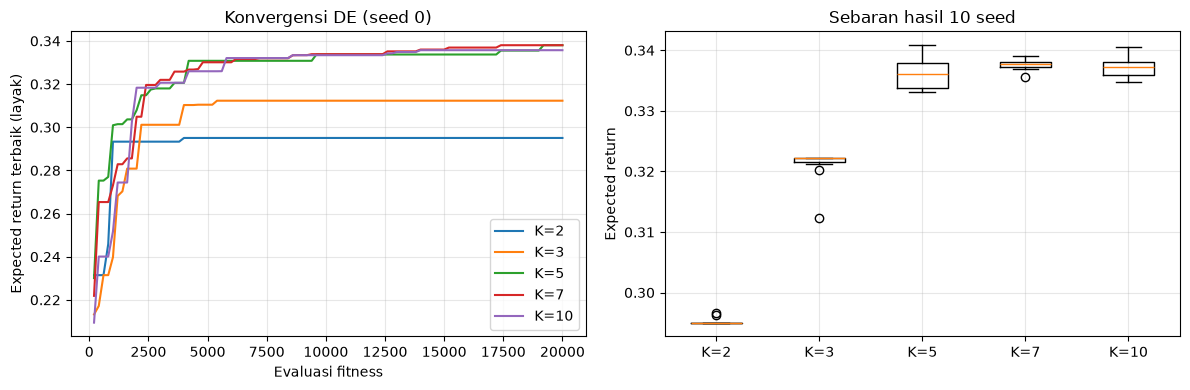

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for K in K_LIST:
    h = hasil_de[K][0]
    xs = [v[0] for v in h.history]
    ys = [v[1] for v in h.history]
    axes[0].plot(xs, ys, label=f'K={K}')
axes[0].set(xlabel='Evaluasi fitness', ylabel='Expected return terbaik (layak)', title='Konvergensi DE (seed 0)')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].boxplot([df_de[df_de.K==K].R for K in K_LIST], tick_labels=[f'K={K}' for K in K_LIST])
axes[1].set(ylabel='Expected return', title='Sebaran hasil 10 seed'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
